
## Sebastian Quintero Granada
**Objetivo:** entrenar (vía fine-tuning) un modelo de lenguaje preentrenado tipo BERT para clasificar automáticamente la emoción expresada en un texto corto, explorando distintos hiperparámetros y seleccionando el mejor modelo.



## 1. Configuración del entorno

In [17]:
!pip install -q -U transformers datasets evaluate accelerate scikit-learn

In [18]:
import os, time, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          set_seed, pipeline)
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import transformers

SEED = 42
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED)
os.environ["WANDB_DISABLED"] = "true"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("transformers:", transformers.__version__)
print("Dispositivo:", device, "-", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
sns.set_theme(style="whitegrid")

transformers: 5.22.1
Dispositivo: cuda - Tesla T4


## 2. Descripción de la base de datos

### 2.1 Dataset seleccionado: dair-ai/emotion
- **Fuente:** Hugging Face Datasets — https://huggingface.co/datasets/dair-ai/emotion  
- **Referencia:** Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018). *CARER: Contextualized Affect Representations for Emotion Recognition*. EMNLP 2018.
Esta en inglés


### 2.2 Dominio del problema
El dataset pertenece al dominio de **análisis de afecto / reconocimiento de emociones** en redes sociales. Está compuesto por mensajes de **Twitter** en inglés, recolectados y etiquetados de forma distante (*distant supervision*) usando hashtags emocionales, y luego depurados. Cada mensaje expresa una de **seis emociones básicas** (basadas en el modelo de Paul Ekman).

### 2.3 Utilidad
Detectar automáticamente la emoción de un texto es útil en:
- **Atención al cliente:** priorizar mensajes con enojo o miedo y escalar casos críticos.
- **Monitoreo de marca y redes sociales:** medir cómo se siente la audiencia frente a un producto o campaña (más fino que solo positivo/negativo).
- **Salud mental y bienestar:** apoyo para detectar señales de tristeza o miedo en plataformas de acompañamiento.
- **Chatbots y asistentes:** adaptar el tono de la respuesta según el estado emocional del usuario.

### 2.4 Datos de entrada y variable de salida


 **Entrada (`text`)** Cadena de texto: un tweet en inglés, en minúsculas, sin URLs ni menciones. |
| **Salida (`label`)** | Entero de 0 a 5 que representa la emoción. |


sadness (tristeza)
 joy (alegría)
 love (amor)
 anger (enojo)
 fear (miedo)
 surprise (sorpresa)

### 2.5 Tipo de problema
**Clasificación de secuencias (*sequence classification*) multiclase** — una sola etiqueta por texto, 6 clases mutuamente excluyentes.

### 2.6 Particiones
El dataset viene dividido oficialmente en **train (16.000)**, **validation (2.000)** y **test (2.000)** ejemplos. Se usa *train* para entrenar, *validation* para comparar hiperparámetros y escoger el mejor modelo, y *test* **solo una vez** al final para reportar el desempeño del modelo ganador.

### 2.7 Métrica principal
Como las clases están **desbalanceadas** (ver EDA), la métrica principal para comparar modelos es el **F1 macro** (promedio simple del F1 de cada clase, que castiga a un modelo que ignore las clases minoritarias). También se reportan *accuracy*, F1 ponderado, precisión y *recall*.

In [20]:
dataset = load_dataset("dair-ai/emotion")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [21]:
label_names = dataset["train"].features["label"].names
id2label = {i: n for i, n in enumerate(label_names)}
label2id = {n: i for i, n in enumerate(label_names)}
print("Clases:", id2label)
print("Features:", dataset["train"].features)

Clases: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
Features: {'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


## 3. Análisis exploratorio de datos (EDA)

In [22]:
df_train = dataset["train"].to_pandas()
df_val   = dataset["validation"].to_pandas()
df_test  = dataset["test"].to_pandas()
for df in (df_train, df_val, df_test):
    df["emotion"] = df["label"].map(id2label)

print("Tamaños -> train:", len(df_train), "| validation:", len(df_val), "| test:", len(df_test))
print("Valores nulos en train:", df_train.isna().sum().sum())
print("Textos duplicados en train:", df_train["text"].duplicated().sum())
df_train.head(10)

Tamaños -> train: 16000 | validation: 2000 | test: 2000
Valores nulos en train: 0
Textos duplicados en train: 31


,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,2,love
4,i am feeling grouchy,3,anger
5,ive been feeling a little burdened lately wasnt sure why that was,0,sadness
6,ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny,5,surprise
7,i feel as confused about life as a teenager or as jaded as a year old man,4,fear
8,i have been with petronas for years i feel that petronas has performed well and made a huge profit,1,joy
9,i feel romantic too,2,love


### 3.1 Ejemplos por emoción
Para entender el problema, se muestran ejemplos reales de cada clase:

In [23]:
pd.set_option("display.max_colwidth", 200)
for lbl in label_names:
    print(f"\n=== {lbl.upper()} ===")
    for t in df_train[df_train["emotion"] == lbl]["text"].sample(3, random_state=SEED):
        print("  •", t)


=== SADNESS ===
  • im feeling so lousy they tried to cheer me up during school time and during choir practice
  • i feel highly disadvantaged
  • i feel humiliated to introduce you to my colleagues as my wife

=== JOY ===
  • i feel im rather innocent in that respect
  • im feeling quite adventurous and tried out those drinks that i just normally read through the pages of pocketbooks
  • im feeling much more positive about the impending move

=== LOVE ===
  • i mean fuck i feel like i was way more considerate with customers and concerned about appearance and sanitiation snoozel pm but fine
  • i remember a couple of years ago i was feeling romantic and dreamy and asked him wonder if we ll celebrate our th anniversary
  • im so going to end up feeling slutty and be like ah

=== ANGER ===
  • i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
  • i feel frustrated sometimes wit

### 3.2 Distribución de clases

,train,validation,test
emotion,,,
sadness,29.16 %,27.5 %,29.05 %
joy,33.51 %,35.2 %,34.75 %
love,8.15 %,8.9 %,7.95 %
anger,13.49 %,13.75 %,13.75 %
fear,12.11 %,10.6 %,11.2 %
surprise,3.58 %,4.05 %,3.3 %


/tmp/ipykernel_1404/2921064586.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, y="emotion", order=order, palette="Blues_r", ax=ax)


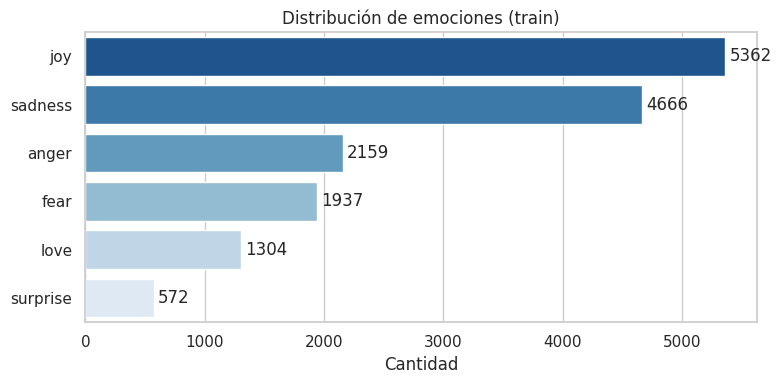

In [24]:
dist = pd.DataFrame({
    "train": df_train["emotion"].value_counts(normalize=True),
    "validation": df_val["emotion"].value_counts(normalize=True),
    "test": df_test["emotion"].value_counts(normalize=True),
}).loc[label_names] * 100
display(dist.round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(8, 4))
order = df_train["emotion"].value_counts().index
sns.countplot(data=df_train, y="emotion", order=order, palette="Blues_r", ax=ax)
for c in ax.containers: ax.bar_label(c, padding=3)
ax.set_title("Distribución de emociones (train)"); ax.set_xlabel("Cantidad"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Observación:** el dataset está **desbalanceado**: *joy* y *sadness* suman cerca del 63 % de los ejemplos, mientras que *surprise* (~3.6 %) y *love* (~8 %) son minoritarias. La distribución es prácticamente la misma en las tres particiones. Por esto se usa **F1 macro** como métrica de selección. No se aplica re-muestreo: se trabaja con la distribución real.

### 3.3 Longitud de los textos

count    16000.00
mean        19.17
std         10.99
min          2.00
25%         11.00
50%         17.00
75%         25.00
max         66.00
Name: n_palabras, dtype: float64


/tmp/ipykernel_1404/3046020183.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x="n_palabras", y="emotion", order=label_names, palette="Blues", ax=axes[1])


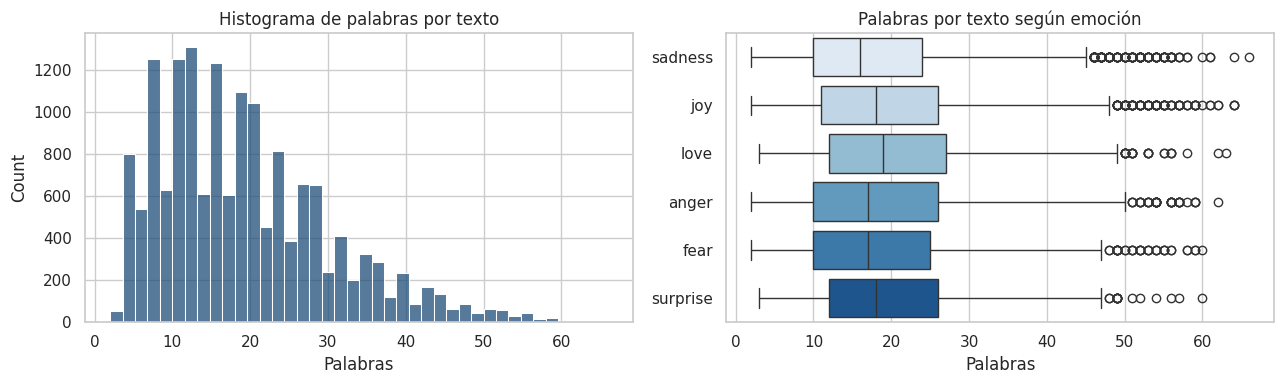

In [25]:
df_train["n_palabras"] = df_train["text"].str.split().str.len()
print(df_train["n_palabras"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_train["n_palabras"], bins=40, color="#1f4e79", ax=axes[0])
axes[0].set_title("Histograma de palabras por texto"); axes[0].set_xlabel("Palabras")
sns.boxplot(data=df_train, x="n_palabras", y="emotion", order=label_names, palette="Blues", ax=axes[1])
axes[1].set_title("Palabras por texto según emoción"); axes[1].set_xlabel("Palabras"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Observación:** los textos son cortos (mediana ≈ 17 palabras, máximo ≈ 66). La longitud es similar entre emociones, así que no es una variable que por sí sola permita distinguirlas: el modelo debe entender el **contenido**.

### 3.4 Palabras más frecuentes por emoción
Se excluyen *stopwords* y la palabra *feel/feeling*, presente en casi todos los textos por la forma en que se construyó el dataset.

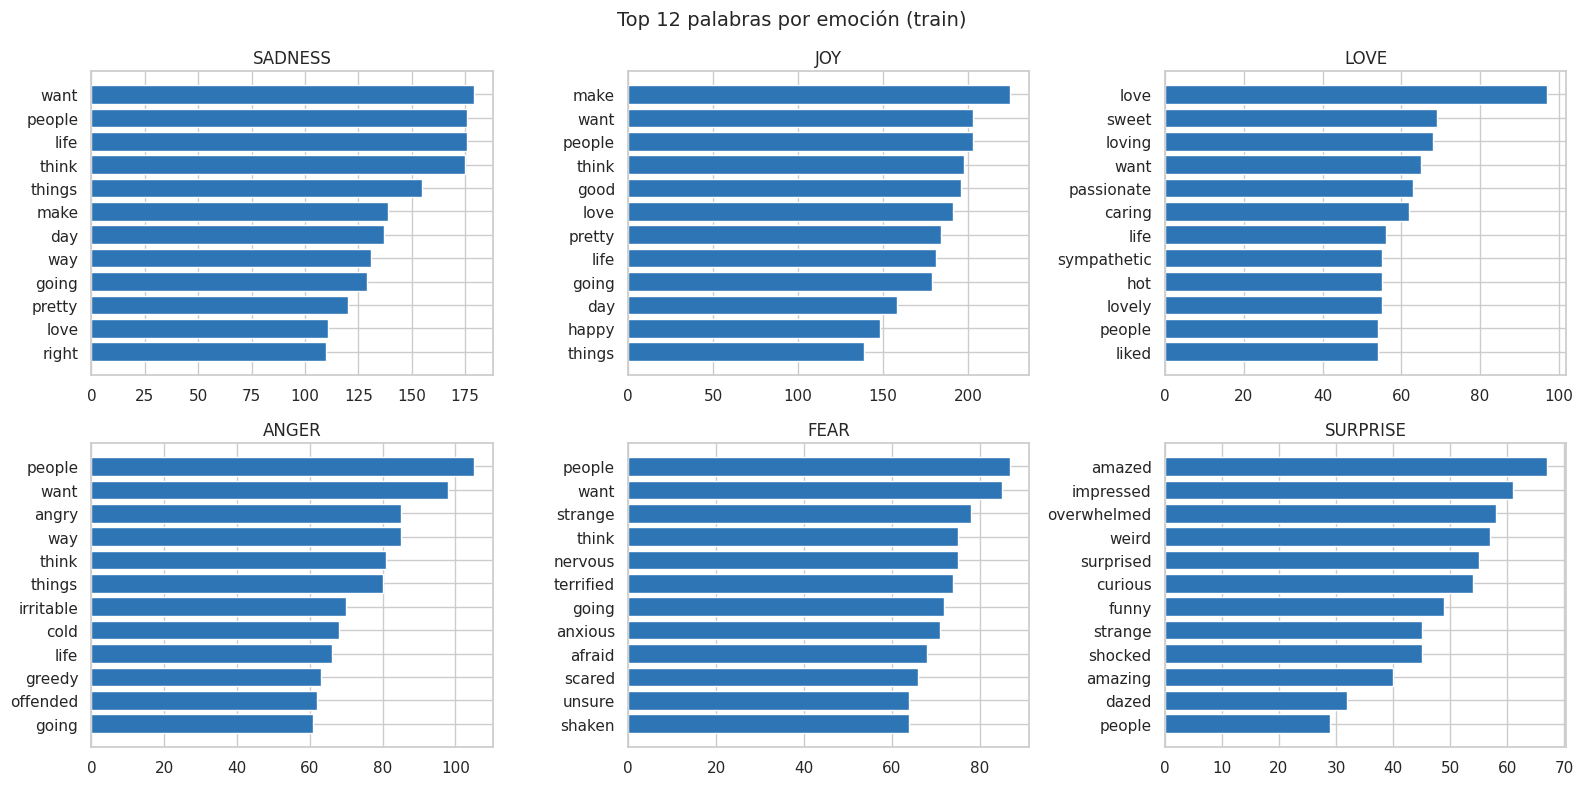

In [26]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
extra = {"feel", "feeling", "feelings", "im", "really", "like", "just", "know", "time", "don", "ive", "dont", "get", "little", "bit"}
stop = set(ENGLISH_STOP_WORDS) | extra

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, lbl in zip(axes.flat, label_names):
    words = " ".join(df_train[df_train["emotion"] == lbl]["text"]).split()
    top = Counter(w for w in words if w not in stop and len(w) > 2).most_common(12)
    w, c = zip(*top)
    ax.barh(w[::-1], c[::-1], color="#2e75b6")
    ax.set_title(lbl.upper())
plt.suptitle("Top 12 palabras por emoción (train)", fontsize=14)
plt.tight_layout(); plt.show()

**Observación:** cada emoción tiene un vocabulario característico (p. ej. *amazed, curious, impressed* en sorpresa; *afraid, anxious, nervous* en miedo; *loving, sweet, caring* en amor). Sin embargo, hay solapamiento (p. ej. *love* vs. *joy*), y el significado depende del contexto y de negaciones (*"I don't feel happy"*). Por eso tiene sentido usar un modelo contextual tipo **Transformer** en lugar de solo contar palabras.

## 4. Preprocesamiento y tokenización

Los modelos tipo BERT no reciben texto, sino **tokens** (sub-palabras con WordPiece) convertidos a IDs, junto con una *attention mask*. Se usa el tokenizador propio de cada modelo preentrenado.

Primero se revisa la longitud en tokens para escoger `max_length` sin truncar casi nada:

In [27]:
MODELOS = {
    "distilbert": "distilbert-base-uncased",
    "bert":       "bert-base-uncased",
}
tok_tmp = AutoTokenizer.from_pretrained(MODELOS["distilbert"])
n_tokens = [len(tok_tmp(t)["input_ids"]) for t in df_train["text"]]
print(pd.Series(n_tokens).describe(percentiles=[.5, .95, .99]).round(1))

ejemplo = df_train["text"].iloc[0]
enc = tok_tmp(ejemplo)
print("\nTexto:   ", ejemplo)
print("Tokens:  ", tok_tmp.convert_ids_to_tokens(enc["input_ids"]))
print("IDs:     ", enc["input_ids"])

count    16000.0
mean        22.3
std         11.6
min          4.0
50%         20.0
95%         45.0
99%         57.0
max         87.0
dtype: float64

Texto:    i didnt feel humiliated
Tokens:   ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]']
IDs:      [101, 1045, 2134, 2102, 2514, 26608, 102]


El percentil 99 está muy por debajo de 128 tokens, así que se fija `MAX_LEN = 128` (en la práctica el *padding* es dinámico por *batch*, lo que acelera el entrenamiento).

In [28]:
MAX_LEN = 128

def tokenizar_dataset(model_ckpt):
    tok = AutoTokenizer.from_pretrained(model_ckpt)
    ds = dataset.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
    return tok, ds

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, preds),
        "f1_macro":    f1_score(labels, preds, average="macro"),
        "f1_weighted": f1_score(labels, preds, average="weighted"),
        "precision_macro": precision_score(labels, preds, average="macro", zero_division=0),
        "recall_macro":    recall_score(labels, preds, average="macro", zero_division=0),
    }

## 5. *Fine-tuning* y búsqueda de hiperparámetros

### 5.1 Estrategia
El *fine-tuning* consiste en tomar un modelo preentrenado sobre grandes corpus (que ya "entiende" el idioma) y añadirle una **cabeza de clasificación** (capa lineal de 6 salidas sobre el token `[CLS]`), reentrenando todos los pesos con nuestro dataset.

Se parte de **DistilBERT** (`distilbert-base-uncased`): una versión destilada de BERT con 40 % menos parámetros (~66 M) y ~60 % más rápida, que conserva ~97 % del desempeño de BERT. Esto permite probar varias combinaciones de hiperparámetros en tiempo razonable.

**Malla de hiperparámetros (6 combinaciones):**
| Hiperparámetro | Valores |
|---|---|
| *Learning rate* | 2e-5, 3e-5, 5e-5 |
| *Batch size* | 16, 32 |

**Fijos:** 3 épocas, *weight decay* = 0.01, *warmup ratio* = 0.1, optimizador AdamW, *scheduler* lineal, *mixed precision* (fp16) en GPU.

Para cada combinación se evalúa en **validación** al final de cada época y se conserva la mejor época según **F1 macro** (`load_best_model_at_end`).

In [41]:
import math

def entrenar(model_key, lr, batch_size, epochs=3, weight_decay=0.01, warmup_ratio=0.1, guardar=False):
    ckpt = MODELOS[model_key]
    tok, ds = TOKENIZADOS[model_key]
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        ckpt, num_labels=len(label_names), id2label=id2label, label2id=label2id)

    run_name = f"{model_key}_lr{lr}_bs{batch_size}_ep{epochs}"
    # warmup como número de pasos (compatible con transformers 4.x y 5.x)
    pasos_totales = math.ceil(len(ds["train"]) / batch_size) * epochs
    warmup_steps = int(warmup_ratio * pasos_totales)
    args = TrainingArguments(
        output_dir=f"runs/{run_name}",
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        logging_strategy="epoch",
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(
        model=model, args=args,
        train_dataset=ds["train"], eval_dataset=ds["validation"],
        data_collator=DataCollatorWithPadding(tok),
        compute_metrics=compute_metrics,
    )
    t0 = time.time()
    trainer.train()
    minutos = (time.time() - t0) / 60
    historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
    m = trainer.evaluate()   # métricas del mejor checkpoint (load_best_model_at_end)

    resultado = {
        "modelo": model_key, "learning_rate": lr, "batch_size": batch_size, "epochs": epochs,
        "val_accuracy": m["eval_accuracy"], "val_f1_macro": m["eval_f1_macro"],
        "val_f1_weighted": m["eval_f1_weighted"], "val_loss": m["eval_loss"],
        "minutos": round(minutos, 2),
    }
    print(f"✔ {run_name}: F1 macro = {m['eval_f1_macro']:.4f} | acc = {m['eval_accuracy']:.4f} | {minutos:.1f} min")

    if not guardar:   # liberar memoria de GPU entre corridas
        del trainer, model; gc.collect(); torch.cuda.empty_cache()
        return resultado, historial, None, tok
    return resultado, historial, trainer, tok

TOKENIZADOS = {k: tokenizar_dataset(v) for k, v in MODELOS.items()}

In [40]:
LEARNING_RATES = [2e-5, 3e-5, 5e-5]
BATCH_SIZES = [16, 32]

resultados, historiales = [], {}
for lr in LEARNING_RATES:
    for bs in BATCH_SIZES:
        res, hist, _, _ = entrenar("distilbert", lr, bs)
        resultados.append(res)
        historiales[f"lr={lr}, bs={bs}"] = hist

df_res = pd.DataFrame(resultados).sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
df_res

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,0.641808,0.196166,0.929000,0.903776,0.929496,0.894504,0.917406
2,0.155364,0.165313,0.931500,0.904033,0.930656,0.915391,0.896729
3,0.101555,0.150088,0.935500,0.913643,0.935545,0.919536,0.909755


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (39 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.085581,0.132187,3,0.942000,0.916864,0.941867,0.925246,0.911846


✔ distilbert_lr5e-05_bs32_ep3: F1 macro = 0.9169 | acc = 0.9420 | 1.6 min


,modelo,learning_rate,batch_size,epochs,val_accuracy,val_f1_macro,val_f1_weighted,val_loss,minutos
0,distilbert,0.00005,16,3,0.9455,0.922969,0.945259,0.144260,2.31
1,distilbert,0.00003,16,3,0.9425,0.919962,0.942169,0.148709,2.46
2,distilbert,0.00005,32,3,0.9420,0.916864,0.941867,0.132187,1.57
3,distilbert,0.00002,16,3,0.9355,0.913643,0.935545,0.150088,2.44
4,distilbert,0.00003,32,3,0.9370,0.913271,0.937152,0.151840,1.54
5,distilbert,0.00002,32,3,0.9365,0.912951,0.936599,0.154407,1.76


### 5.2 Análisis de los resultados de la malla

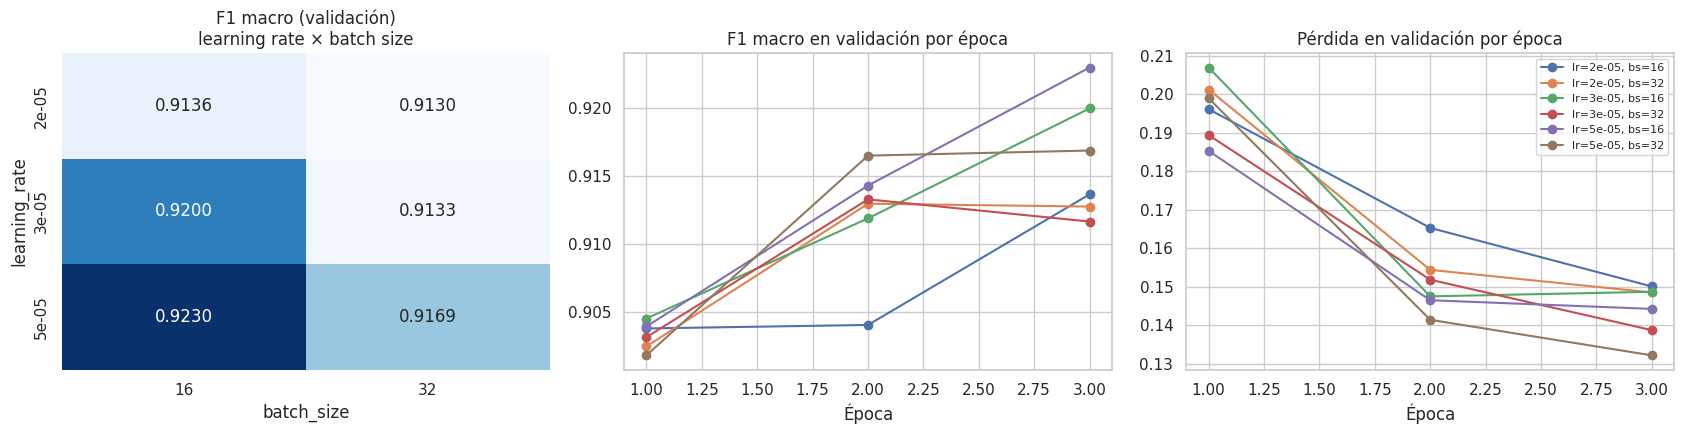

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

piv = df_res.pivot(index="learning_rate", columns="batch_size", values="val_f1_macro")
sns.heatmap(piv, annot=True, fmt=".4f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("F1 macro (validación)\nlearning rate × batch size")

for nombre, h in historiales.items():
    axes[1].plot(h["epoch"], h["eval_f1_macro"], marker="o", label=nombre)
    axes[2].plot(h["epoch"], h["eval_loss"], marker="o", label=nombre)
axes[1].set_title("F1 macro en validación por época"); axes[1].set_xlabel("Época")
axes[2].set_title("Pérdida en validación por época"); axes[2].set_xlabel("Época")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación (completar con los valores obtenidos):**
- El *learning rate* es el hiperparámetro más sensible: valores muy bajos convergen más lento en 3 épocas; valores altos aprenden rápido pero pueden aumentar la pérdida de validación en las últimas épocas (señal de sobreajuste).
- Con *batch size* más pequeño hay más actualizaciones de pesos por época, lo que suele compensar un *learning rate* bajo.
- La curva de pérdida de validación permite ver si conviene más o menos épocas.

## 6. Comparación de arquitecturas: DistilBERT vs. BERT-base

Con la mejor combinación de hiperparámetros encontrada para DistilBERT, se entrena **BERT-base** (`bert-base-uncased`, ~110 M parámetros, 12 capas) para comparar si el modelo más grande compensa su mayor costo computacional. Adicionalmente se prueba la mejor configuración de DistilBERT con **5 épocas**, para verificar si más entrenamiento ayuda.

In [31]:
mejor_dist = df_res.iloc[0]
best_lr, best_bs = float(mejor_dist["learning_rate"]), int(mejor_dist["batch_size"])
print(f"Mejor DistilBERT: lr={best_lr}, batch_size={best_bs}, F1 macro val={mejor_dist['val_f1_macro']:.4f}")

extra = []
res, hist, _, _ = entrenar("distilbert", best_lr, best_bs, epochs=5); extra.append(res)
res, hist, _, _ = entrenar("bert", best_lr, best_bs, epochs=3);       extra.append(res)

df_todos = pd.concat([df_res, pd.DataFrame(extra)]).sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
df_todos.style.background_gradient(subset=["val_f1_macro"], cmap="Blues").format(precision=4)

Mejor DistilBERT: lr=5e-05, batch_size=16, F1 macro val=0.9230


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,0.593641,0.217050,0.927000,0.901753,0.927853,0.888706,0.921534
2,0.156106,0.168684,0.937500,0.912271,0.936962,0.919804,0.908082
3,0.118277,0.160823,0.939000,0.913097,0.939010,0.918039,0.909874
4,0.077434,0.228608,0.933500,0.909477,0.933497,0.906191,0.914731
5,0.043760,0.266912,0.939000,0.913841,0.938888,0.916355,0.911468


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (13 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.091351,0.161534,3,0.942500,0.920458,0.942347,0.927497,0.914960


✔ bert_lr5e-05_bs16_ep3: F1 macro = 0.9205 | acc = 0.9425 | 4.5 min


,modelo,learning_rate,batch_size,epochs,val_accuracy,val_f1_macro,val_f1_weighted,val_loss,minutos
0,distilbert,0.0001,16,3,0.9455,0.9230,0.9453,0.1443,2.2000
1,bert,0.0001,16,3,0.9425,0.9205,0.9423,0.1615,4.5500
2,distilbert,0.0000,16,3,0.9425,0.9200,0.9422,0.1487,2.2900
3,distilbert,0.0001,32,3,0.9420,0.9169,0.9419,0.1322,1.6200
4,distilbert,0.0001,16,5,0.9390,0.9138,0.9389,0.2669,3.7300
5,distilbert,0.0000,16,3,0.9355,0.9136,0.9355,0.1501,2.3800
6,distilbert,0.0000,32,3,0.9370,0.9133,0.9372,0.1518,1.5500
7,distilbert,0.0000,32,3,0.9365,0.9130,0.9366,0.1544,1.5700


/tmp/ipykernel_1404/2948466787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, y="config", x="val_f1_macro", palette="Blues_r", ax=ax)


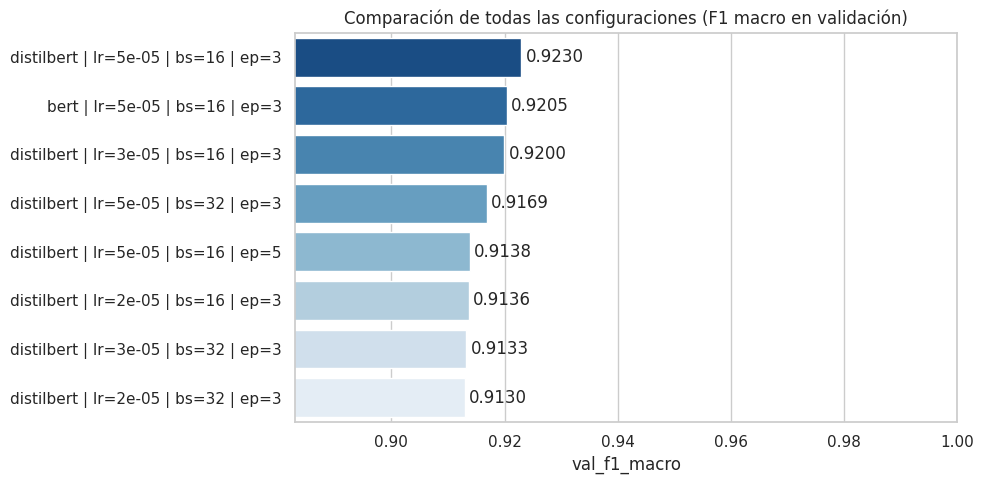

In [32]:
df_plot = df_todos.copy()
df_plot["config"] = df_plot.apply(lambda r: f"{r.modelo} | lr={r.learning_rate:g} | bs={int(r.batch_size)} | ep={int(r.epochs)}", axis=1)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df_plot, y="config", x="val_f1_macro", palette="Blues_r", ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.4f", padding=3)
ax.set_xlim(df_plot["val_f1_macro"].min() - 0.03, 1.0)
ax.set_title("Comparación de todas las configuraciones (F1 macro en validación)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 7. Mejor modelo encontrado

Se selecciona la configuración con mayor **F1 macro en validación**, se reentrena (misma semilla → mismo resultado) conservando el modelo y se evalúa **una única vez** en el conjunto de **prueba**, que no se usó para ninguna decisión.

In [33]:
best = df_todos.iloc[0]
print("MEJOR CONFIGURACIÓN")
print(best[["modelo", "learning_rate", "batch_size", "epochs", "val_f1_macro", "val_accuracy"]])

res_best, hist_best, trainer_best, tok_best = entrenar(
    best["modelo"], float(best["learning_rate"]), int(best["batch_size"]),
    epochs=int(best["epochs"]), guardar=True)

MEJOR CONFIGURACIÓN
modelo           distilbert
learning_rate       0.00005
batch_size               16
epochs                    3
val_f1_macro       0.922969
val_accuracy         0.9455
Name: 0, dtype: object


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,0.521170,0.185334,0.929500,0.903920,0.930493,0.888938,0.926786
2,0.135456,0.146515,0.938500,0.914288,0.937859,0.926688,0.903866
3,0.085810,0.144260,0.945500,0.922969,0.945259,0.929782,0.916786


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.085810,0.144260,3,0.945500,0.922969,0.945259,0.929782,0.916786


✔ distilbert_lr5e-05_bs16_ep3: F1 macro = 0.9230 | acc = 0.9455 | 2.5 min


In [34]:
_, ds_best = TOKENIZADOS[best["modelo"]]
pred = trainer_best.predict(ds_best["test"])
y_true = pred.label_ids
y_pred = np.argmax(pred.predictions, axis=-1)

print("=== DESEMPEÑO EN TEST ===")
for k, v in pred.metrics.items():
    if k.startswith("test_") and not k.endswith(("runtime", "per_second")):
        print(f"{k:28s}: {v:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=label_names, digits=4))

=== DESEMPEÑO EN TEST ===
test_loss                   : 0.1618
test_accuracy               : 0.9295
test_f1_macro               : 0.8874
test_f1_weighted            : 0.9288
test_precision_macro        : 0.8967
test_recall_macro           : 0.8800

              precision    recall  f1-score   support

     sadness     0.9674    0.9690    0.9682       581
         joy     0.9420    0.9583    0.9501       695
        love     0.8913    0.7736    0.8283       159
       anger     0.9161    0.9127    0.9144       275
        fear     0.8734    0.9241    0.8980       224
    surprise     0.7903    0.7424    0.7656        66

    accuracy                         0.9295      2000
   macro avg     0.8967    0.8800    0.8874      2000
weighted avg     0.9291    0.9295    0.9288      2000



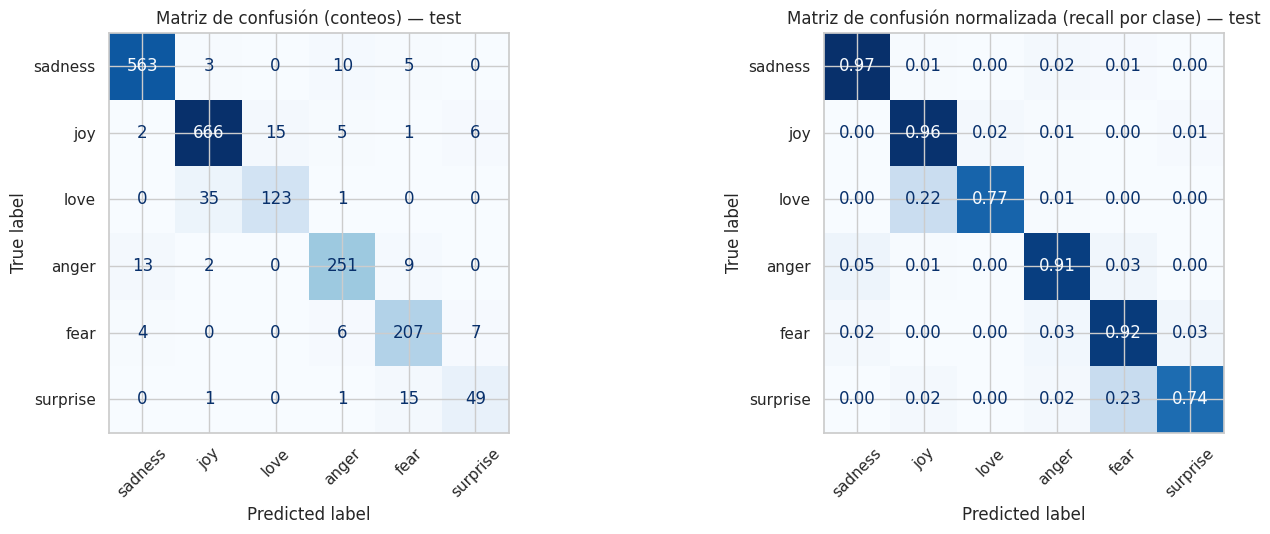

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusión (conteos) — test")
cm_n = confusion_matrix(y_true, y_pred, normalize="true")
ConfusionMatrixDisplay(cm_n, display_labels=label_names).plot(cmap="Blues", ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Matriz de confusión normalizada (recall por clase) — test")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 7.1 Análisis de errores
Ejemplos del conjunto de prueba que el modelo clasificó mal:

In [36]:
df_err = df_test.copy()
df_err["pred"] = [id2label[p] for p in y_pred]
df_err = df_err[df_err["emotion"] != df_err["pred"]]
print(f"Errores: {len(df_err)} de {len(df_test)} ({len(df_err)/len(df_test):.1%})\n")
print("Confusiones más frecuentes:")
display(df_err.groupby(["emotion", "pred"]).size().sort_values(ascending=False).head(6).rename("n").to_frame())
df_err[["text", "emotion", "pred"]].sample(min(10, len(df_err)), random_state=SEED)

Errores: 141 de 2000 (7.0%)

Confusiones más frecuentes:


,,n
emotion,pred,
love,joy,35
joy,love,15
surprise,fear,15
anger,sadness,13
sadness,anger,10
anger,fear,9


,text,emotion,pred
1003,i started walking again yesterday and it feels amazing,joy,surprise
1560,i feel helpless to regain a safe feeling,sadness,fear
502,i am feeling stressed and more than a bit anxious,anger,sadness
816,whenever i put myself in others shoes and try to make the person happy,anger,joy
1382,i cannot even begin to express in words the depth of sorrow that i feel having not posted any of my ludicrous rants over the passed days,surprise,anger
1943,i didn t mean to get angry with you bommie i just can t control my feelings hellip i just hated myself why i am like this the dara who can t get over with that b,sadness,anger
1185,i start to feel a little overwhelmed knowing i have to make still,surprise,fear
1708,i just tell people i feel like one sweet southern mess right now,joy,love
1928,i feel inside cause life is like a game sometimes but then you came around me the walls just disappeared nothing to surround me and keep me from my fears im unprotected see how ive opened up youve...,fear,sadness
234,i love to dance but often feel inhibited by my own body unsure what i am capable of hyper concerned about other people watching me and having opinions on my style or just feeling awkward as if i h...,fear,sadness


Las confusiones más comunes suelen darse entre emociones **semánticamente cercanas**: *love ↔ joy* (ambas positivas) y *fear ↔ surprise* (ambas implican reacción ante algo inesperado), además de *anger ↔ sadness*. Varias de estas etiquetas son ambiguas incluso para una persona, ya que provienen de supervisión distante con hashtags.

### 7.2 Guardar el mejor modelo

In [37]:
RUTA = "mejor_modelo_emociones"
trainer_best.save_model(RUTA)
tok_best.save_pretrained(RUTA)
print("Modelo guardado en:", RUTA)

# Opcional: publicar en el Hub de Hugging Face (requiere notebook_login de la sección 1)
# trainer_best.push_to_hub("bert-emotion-classifier")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en: mejor_modelo_emociones


## 8. Inferencia con textos nuevos
Se usa el mejor modelo con un `pipeline` de Hugging Face sobre frases que no están en el dataset:

In [38]:
clasificador = pipeline("text-classification", model=RUTA, tokenizer=RUTA,
                        device=0 if torch.cuda.is_available() else -1, top_k=None)

frases = [
    "I finally got the job offer, I can't stop smiling!",
    "I miss my grandmother so much since she passed away",
    "I can't believe they cancelled my flight again without any notice",
    "I'm so nervous about tomorrow's final exam",
    "I adore the way you always take care of me",
    "Wow, I never expected to see you here after so many years",
]
for f in frases:
    scores = sorted(clasificador(f)[0], key=lambda x: -x["score"])
    top = ", ".join(f"{s['label']} {s['score']:.2f}" for s in scores[:3])
    print(f"{f}\n   → {scores[0]['label'].upper()}   ({top})\n")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

I finally got the job offer, I can't stop smiling!
   → JOY   (joy 1.00, surprise 0.00, anger 0.00)

I miss my grandmother so much since she passed away
   → SADNESS   (sadness 1.00, anger 0.00, joy 0.00)

I can't believe they cancelled my flight again without any notice
   → SADNESS   (sadness 0.64, anger 0.35, joy 0.00)

I'm so nervous about tomorrow's final exam
   → FEAR   (fear 1.00, surprise 0.00, anger 0.00)

I adore the way you always take care of me
   → LOVE   (love 0.82, joy 0.14, sadness 0.03)

Wow, I never expected to see you here after so many years
   → JOY   (joy 0.95, surprise 0.02, anger 0.02)



## 9. Conclusiones

1. **Problema y datos.** Se abordó un problema de **clasificación de secuencias multiclase** (6 emociones) sobre 20.000 tweets en inglés del dataset `dair-ai/emotion`. El EDA mostró textos cortos (~17 palabras), sin nulos, y un **desbalance** importante (*joy* y *sadness* dominan; *surprise* y *love* son minoritarias), por lo que se usó **F1 macro** como métrica de selección.
2. ***Fine-tuning*.** Ajustar un Transformer preentrenado permite alcanzar un desempeño alto con pocas épocas, porque el modelo ya trae conocimiento del lenguaje y solo debe especializarse en la tarea.
3. **Hiperparámetros.** Se probaron 6 combinaciones de *learning rate* × *batch size* en DistilBERT, más una variante con más épocas y una arquitectura más grande (BERT-base). El *learning rate* fue el hiperparámetro más influyente.
4. **Mejor modelo.** La configuración ganadora y sus métricas en *test* están en la sección 7. Los errores restantes se concentran en pares de emociones cercanas (*love/joy*, *fear/surprise*), lo cual es coherente con la ambigüedad propia de las etiquetas.
5. **Trabajo futuro.** Probar modelos más recientes (RoBERTa, DeBERTa-v3), ponderar la función de pérdida por clase para mejorar *surprise* y *love*, o aplicar el mismo enfoque a un dataset en español con un modelo como BETO (`dccuchile/bert-base-spanish-wwm-cased`).

